# NEURAL NETWORK IMPLEMENTATION

Implementing simple neural network for churn prediction with given churn dataset.
Machin learning pipeline which can predict the customer churn with high precission.

1. Making simple data cleaning with the dataset
2. Build the neural network with torch
3. Conclusion with neural network

Success metrics
+ Pression : Number of predicted churners who actually churns
+ Recall : people which we actually identified | correct classification
+ f1-score : Balanced measure for imbalanced dataset
+ AUC-ROC : Overall discriminative ablity 

Buisness Impact -- Need to ponder beyond treditional ml pipelin overview
+ Revenue retension : percentage of total profit made
+ Campain efficiency : ROI of targets which suggested
+ Long term revenue impact

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
from rich import print

raw_df = pd.read_csv('/home/madhav/workstation/Lab/experiment/data/tele-churn.csv')

raw_df.columns, raw_df.shape

(Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
        'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
        'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
        'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
       dtype='str'),
 (7043, 21))

In [100]:
raw_df['TotalCharges'] = pd.to_numeric(raw_df['TotalCharges'], errors='coerce')

raw_df = raw_df.dropna()

maping = {'Yes': 1, 'No':0}
raw_df['Churn'] = raw_df['Churn'].map(maping)

raw_df.info()

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   str    
 1   gender            7032 non-null   str    
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   str    
 4   Dependents        7032 non-null   str    
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   str    
 7   MultipleLines     7032 non-null   str    
 8   InternetService   7032 non-null   str    
 9   OnlineSecurity    7032 non-null   str    
 10  OnlineBackup      7032 non-null   str    
 11  DeviceProtection  7032 non-null   str    
 12  TechSupport       7032 non-null   str    
 13  StreamingTV       7032 non-null   str    
 14  StreamingMovies   7032 non-null   str    
 15  Contract          7032 non-null   str    
 16  PaperlessBilling  7032 non-null   str    
 17  PaymentMeth

(7032, 21)

<Axes: title={'center': 'Churn probability with payment bins'}, xlabel='payment_group'>

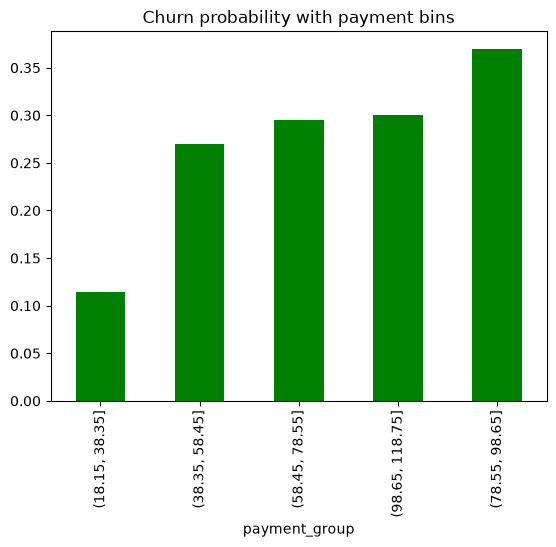

In [101]:
# What is the probability of customer churning if he falls with one bin of total charges
df = raw_df

print(df.shape)
# swap with Monthlycharges and TotalCharges for the trend analyiss of numerical dataset
payment_group = pd.cut(df['MonthlyCharges'], bins=5)

df['payment_group'] = payment_group

churned = df.groupby('payment_group')['Churn'].mean().sort_values()

# Final plot of customer payment interval distribution with churn probability distribution
churned.plot(kind='bar', color='green', title='Churn probability with payment bins')

# With simple conclusion of watching a trend with dataset about customer churning, with low total payment needs more attention

PaymentMethod
Bank transfer (automatic)    0.167315
Credit card (automatic)      0.152531
Electronic check             0.452854
Mailed check                 0.192020
Name: Churn, dtype: float64

<Axes: xlabel='PaymentMethod'>

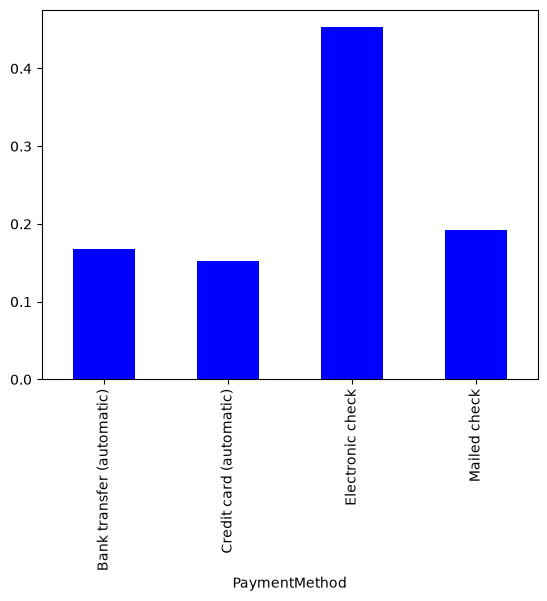

In [102]:
# RELATION OF PAYMENT METHOD WITH CHURNING RATIO OF CUSTOMER
pay_meth_churn_ratio = df.groupby('PaymentMethod')['Churn'].mean()

print(pay_meth_churn_ratio)
pay_meth_churn_ratio.plot(kind='bar', color='blue')

In [103]:
# trian test split
from sklearn.model_selection import train_test_split

# Loading into main dataset
y = df['Churn']

df = df.drop(columns=['customerID', 'Churn'])
X = df

X_train_val, X_test, y_train_val, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val,  test_size=0.2, random_state=42)

In [104]:
print(X_train.columns)

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'payment_group'],
      dtype='str')

In [105]:
# Encoder
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
import numpy as np

# target lock
onehot_targets = ['gender', 'SeniorCitizen', 'Dependents', 'OnlineSecurity', 'StreamingMovies']
ordinal_targets = ['payment_group']
targets = ['payment_group', 'StreamingMovies', 'PaymentMethod']

# Preprocessing transformer
transf = ColumnTransformer(
    [
        ('Onehot process', OneHotEncoder(drop='first'), onehot_targets),
        ('Ordinal sequence', OrdinalEncoder(),  ordinal_targets),
        ('Targeted locks', TargetEncoder(), targets)
    ]
)

X_train = transf.fit_transform(X_train, y_train)

# Class weights initiation for the neural model
from sklearn.utils.class_weight import compute_class_weight

uniq_class = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=uniq_class, y=y_train)
class_weight = dict(zip(uniq_class, weights))
print(class_weight)

device = 'cuda'


{np.int64(0): np.float64(0.6801692865779927), np.int64(1): np.float64(1.8875838926174497)}

In [106]:
# Bench marking with treditiona ML Model | Decission tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

''' 
With referencing decissiontree classifier object with alias at import
we raise critical bug of whatever data frame we pass on to the model, 

Since model was never initiated thus the model never works out,
it wont be able to map out things, parameter handling, 
since we are pointing to the blueprint,, 
Not a existing model to work with
'''

model = DecisionTreeClassifier(class_weight='balanced')

model.fit(X_train, y_train)

# Prediction needs the test dataset to be preprocessed with the exact trained pipeline
X_test = transf.transform(X_test)

preds = model.predict(X_test)


# Choose the averaging method that fits your data:
macro_f1 = f1_score(y_test, preds, average='macro')
micro_f1 = f1_score(y_test, preds, average='micro')
weighted_f1 = f1_score(y_test, preds, average='weighted')

print(f"Macro F1: {macro_f1:.2f}")
print(f"Micro F1: {micro_f1:.2f}")
print(f"Weighted F1: {weighted_f1:.2f}")

Macro F1: 0.61

Micro F1: 0.66

Weighted F1: 0.68

In [107]:
# Loading dataset into torch tensors for neural network chunk
import torch
import numpy as np

# X_test and train are loaded into numpy | loading targets into numpy frame
y_train = np.array(y_train)
y_test = np.array(y_test)
y_val = np.array(y_val)

X_val = transf.transform(X_val)

# For Classification Tasks (Most Common)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)

In [108]:
# Neural netowork setup
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import torch.optim as optim

''' 
functional : function style implementation for layer
lr_scheduler : Learning ledge scheduler for learning rate organization
metrics : reporting and evaluation tools
optim : optimization tools | Adam like optimization variant for gradient algorithms

Need to read the docs **
''' 

# Neural Network Implementation with torch

class ChurnPredictor(nn.Module):
    def __init__(self, input_size, hidden_sizes=[256,128, 64], dropout_rate=0.2):
        super(ChurnPredictor, self).__init__()
        '''
        Base constructor
        - Internal machine starts
        - Enables all api
        - Parameters management
        - All loaders for model functionality
        - Layers and prameter registration and containers
        ''' 
        # Dynamic Build cycle
        layers = []
        prev_size = input_size

        for i,hidden_size in enumerate(hidden_sizes):
            layers.append(nn.Linear(prev_size, hidden_size))  # Linear layer

            # Batch Normalization
            layers.append(
                nn.BatchNorm1d(hidden_size)
            )

            # Activation
            layers.append(nn.ReLU())

            # Dropout
            layers.append(nn.Dropout(dropout_rate))
            prev_size = hidden_size

        layers.append(nn.Linear(prev_size, 1)) # Output layer

        # Loading layers | python list -> network layers
        self.network = nn.Sequential(*layers)

        self._initialize_weights()

    def _initialize_weights(self):
        ''' 
        We target linear layers of the model
        initiate with xavier uniform weights
        set all bias to be constatant zero.
        ''' 

        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.constant_(module.bias,0)

    def forward(self, x):
        return self.network(x)

device = 'cuda'


In [109]:
input_size = X_train_tensor.shape[1]

# Initiating custom churn prediction model
model = ChurnPredictor(input_size=input_size).to(device)

# class weight initiation
pos_weight_tensor = torch.tensor(
    [class_weight[1]],dtype=torch.float32
).to(device)

# Loss criterion | binary cross entropy X logistic loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

# Optimizer definition
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

# Scheduling optimizer
scheduler = ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=10
)

print(model)


ChurnPredictor(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [110]:
# Training function
''' 
We have not used data loaders
due to data size is too much small, 

it could be used in large dataset cases , 
with shuffle and batch based loading facilities.
''' 

def train_epotch(model, X_train, y_train, optimizer, criterion):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train).squeeze() # forward pass
    loss = criterion(outputs, y_train) # loss computation

    loss.backward() # gradient computation
    optimizer.step() # Updates weights
    return loss.item() # Final loss

# Validation function

def validate_epotch(model, X_val, y_val, criterion):
    ''' 
    Requried for giving direction to the actual model,
    with heading with no changes into the  performace, 
    change learning rate
    ''' 
    model.eval()  # model into evaluation mode | turns off dropouts
    with torch.no_grad():  # no auto grad switch turned off | disable gradient updates
        outputs = model(X_val).squeeze()
        loss = criterion(outputs, y_val)

        predictions = torch.sigmoid(outputs)
        predicted_class = (predictions > 0.5).float()
        accuracy = (predicted_class == y_val).float().mean()  # threshhold cascade result
    return loss.item(), accuracy.item(), predicted_class.cpu().numpy()


In [111]:
from sklearn.metrics import f1_score
# TRAINING LOOP

epochs = 500
best_val_loss = float("inf")
patience_counter = 0
patience_limit = 25

train_losses = []
val_losses = []
val_accuracies = []

best_model_path = "BestModel.pth"

for epoch in range(epochs):

    train_loss = train_epotch(
        model, X_train_tensor, y_train_tensor,
        optimizer, criterion
    )

    val_loss, val_accuracy, val_predictions = validate_epotch(
        model, X_val_tensor, y_val_tensor, criterion
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    current_lr = optimizer.param_groups[0]["lr"]

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch: {epoch + 1:3d} | "
            f"Train loss: {train_loss:.5f} | "
            f"Val loss: {val_loss:.5f} | "
            f"f1: {val_accuracy:.4f} | "
            f"LR: {current_lr:.7g}"
        )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        f1 = f1_score(y_val_tensor.cpu().numpy(), val_predictions)

    else:
        patience_counter += 1

    if patience_counter >= patience_limit:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best validation-loss checkpoint
model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

print(f"Best validation loss: {best_val_loss:.5f}, f1 score : {f1}")


Epoch:   1 | Train loss: 1.28782 | Val loss: 0.86831 | f1: 0.3253 | LR: 0.001

Epoch:  10 | Train loss: 0.99614 | Val loss: 0.85379 | f1: 0.3671 | LR: 0.001

Epoch:  20 | Train loss: 0.88262 | Val loss: 0.86558 | f1: 0.4871 | LR: 0.0005

Epoch:  30 | Train loss: 0.83180 | Val loss: 0.80410 | f1: 0.5716 | LR: 0.0005

Epoch:  40 | Train loss: 0.79129 | Val loss: 0.76263 | f1: 0.6640 | LR: 0.0005

...

Epoch: 110 | Train loss: 0.70874 | Val loss: 0.68978 | f1: 0.7156 | LR: 0.0005

Epoch: 120 | Train loss: 0.70843 | Val loss: 0.68974 | f1: 0.7147 | LR: 0.0005

Epoch: 130 | Train loss: 0.71011 | Val loss: 0.69015 | f1: 0.7111 | LR: 0.00025

Early stopping at epoch 138

Best validation loss: 0.68948, f1 score : 0.5604395604395604

Text(0.5, 1.0, 'Validation Accuracy')

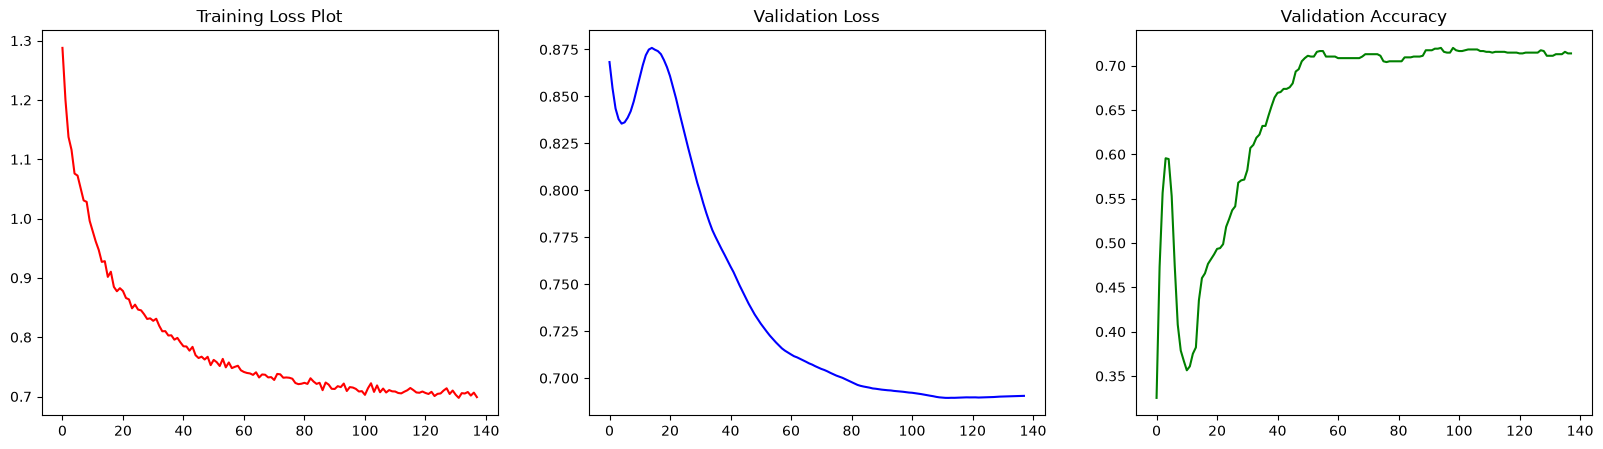

In [112]:
# Loss visualization plots
import seaborn as sns 
import numpy as np
import matplotlib.pyplot as plt 


# Model analysis report
fig, axs = plt.subplots(1,3, figsize=(20,5))

sns.lineplot(train_losses, ax=axs[0], color='red')
axs[0].set_title('Training Loss Plot')

sns.lineplot(val_losses, ax=axs[1], color='blue')
axs[1].set_title('Validation Loss')

sns.lineplot(val_accuracies, ax=axs[2], color='green')
axs[2].set_title('Validation Accuracy')